____
__Universidad Tecnológica Nacional, Buenos Aires__<br/>
__Ingeniería Industrial__<br/>
__Cátedra de Ciencia de Datos - Curso I5521__<br/>
__Trabajo Práctico Final - Alumno: Rodrigo Alejandro Muñoz Vera__
____
# TP Final - Telco Churn
# Análisis Exploratorio de Datos (EDA)

**Consigna:** la empresa Telco NN nos pidió ayuda para predecir qué clientes van a dejar la compañía (churn). Nos dieron un dataset con 7.043 clientes y 21 variables.

**¿Qué vamos a hacer en este notebook?** Antes de armar cualquier modelo tenemos que conocer los datos. Como vimos en clase, si los datos están mal el modelo aprende mal. Por eso en el EDA vamos a:
1. Ver la estructura del dataset y si los tipos de datos están bien.
2. Buscar valores faltantes, duplicados y outliers.
3. Analizar cada variable y, sobre todo, cuáles se relacionan con el churn.

Al final sacamos conclusiones que nos sirven para el preprocesamiento y para el modelado.

## Paso 1: Importamos las librerías

In [1]:
# Importar paquetes de herramientas:
# Datos
import pandas as pd
import numpy as np
# Graficos
import matplotlib.pyplot as plt
import seaborn as sns
# Estadística (skew lo usamos en el notebook de Subtes II)
from scipy.stats import skew
# Otros
import warnings
warnings.filterwarnings('ignore')


## Paso 2: Cargamos el dataset y miramos su estructura

In [2]:
# Cargamos el dataset
df = pd.read_csv('telco_churn_clusterai.csv')
print(f'Shape: {np.shape(df)}')

Shape: (7043, 22)


In [3]:
df.head()

,Unnamed: 0,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,7590-VHVEG,Female,NaN,Yes,No,1.0,No,No phone service,DSL,...,No,No,No,No,Month-to-month,NaN,Electronic check,29.85,29.85,No
1,1,5575-GNVDE,Male,0.0,No,No,34.0,Yes,No,NaN,...,Yes,No,No,No,One year,No,Mailed check,NaN,1889.5,No
2,2,3668-QPYBK,Male,0.0,No,No,2.0,NaN,No,NaN,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,3,7795-CFOCW,Male,0.0,No,No,NaN,No,NaN,NaN,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,4,9237-HQITU,Female,NaN,NaN,NaN,2.0,Yes,No,Fiber optic,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,151.65,Yes


In [4]:
df.dtypes

Unnamed: 0            int64
customerID              str
gender                  str
SeniorCitizen       float64
Partner                 str
Dependents              str
tenure              float64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

**¿Qué vemos?**
- El dataset tiene 7.043 filas (clientes) y 22 columnas. Una más de las que dice la consigna: `Unnamed: 0`, que es el índice que quedó guardado cuando exportaron el CSV. No es información del cliente, así que la vamos a sacar.
- `TotalCharges` aparece como texto (`str`/`object`) y debería ser un número. Algo raro tiene adentro.
- `SeniorCitizen` es 0 o 1, pero aparece como `float`. Eso pasa cuando una columna de enteros tiene valores vacíos (NaN es float).

Vamos a ver qué hay en `TotalCharges` que no es un número:

In [5]:
# convertimos a número; lo que no se pueda convertir queda como NaN
tc = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Cantidad de valores que no son números:', tc.isna().sum())

Cantidad de valores que no son números: 11


In [6]:
# como son pocas lineas llamamos a la tabla en los campos mas relevantes para entender los datos
df[tc.isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0.0,52.55,
753,3115-CZMZD,NaN,20.25,
936,5709-LVOEQ,0.0,80.85,
1082,4367-NUYAO,0.0,25.75,
1340,1371-DWPAZ,0.0,NaN,
3331,7644-OMVMY,0.0,19.85,
3826,3213-VVOLG,0.0,25.35,
4380,2520-SGTTA,0.0,20.00,
5218,2923-ARZLG,0.0,19.70,
6670,4075-WKNIU,0.0,73.35,


**Conclusión:** son 11 clientes que tienen un espacio en blanco `' '` en `TotalCharges`, y todos tienen `tenure = 0` (salvo uno que tiene tenure vacío). Son clientes que podemos entender **recién se dieron de alta** y todavía no pagaron nada, así que su gasto total en realidad es 0. 

In [7]:
# sacamos la columna del índice y pasamos TotalCharges a número
df = df.drop(columns=['Unnamed: 0'])
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# creamos una columna con el churn en 0/1 para poder calcular tasas (promedio = % de churn)
df['churn_num'] = 0
df.loc[df['Churn'] == 'Yes', 'churn_num'] = 1

# separamos las variables numéricas de las categóricas
numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']
categoricas = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
               'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
               'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
print('Variables numéricas:', len(numericas))
print('Variables categóricas:', len(categoricas))

Variables numéricas: 3
Variables categóricas: 16


**Conclusión:** tenemos 3 variables numéricas y 16 categóricas. `SeniorCitizen` la tomamos como categórica (sí/no). `customerID` es solo un identificador (distinto para cada cliente), así que **no sirve para predecir** y no lo vamos a meter en el modelo.

## Paso 3: Valores faltantes

**¿Por qué lo hacemos?** Si le pasamos datos con NaN al modelo tira error. Asi que tenemos que decidir si borramos esas filas o si las rellenamos (imputamos). Para decidir bien hay que saber **cuántos** faltantes hay y **por qué** faltan.

In [8]:
# cantidad y porcentaje de faltantes por columna
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])
faltantes = missing_data[missing_data['Total'] > 0]
faltantes

,Total,Percent
PaymentMethod,1197,0.169956
MonthlyCharges,1197,0.169956
Contract,1197,0.169956
PaperlessBilling,1197,0.169956
gender,916,0.130058
SeniorCitizen,916,0.130058
OnlineBackup,916,0.130058
tenure,916,0.130058
Partner,916,0.130058
Dependents,916,0.130058


In [9]:
# ¿cuántos clientes tienen todos los datos completos?
faltantes_por_fila = df.isna().sum(axis=1)
completas = (faltantes_por_fila == 0).sum()
print('Clientes sin ningún faltante:', completas, 'de', len(df), '->', round(completas / len(df) * 100, 1), '%')

Clientes sin ningún faltante: 844 de 7043 -> 12.0 %


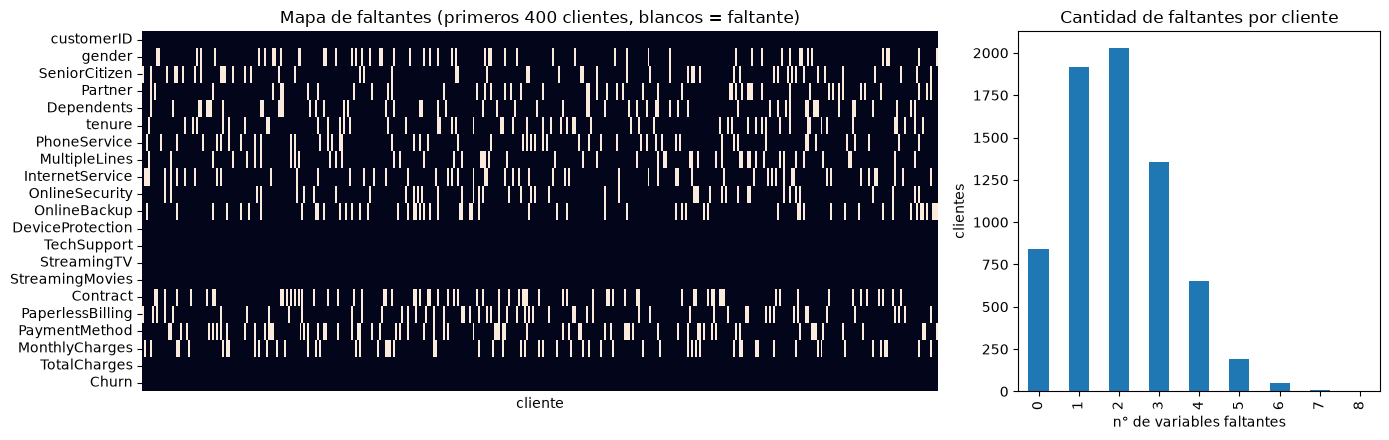

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})
# mapa de faltantes de los primeros 400 clientes (blanco = falta el dato)
sns.heatmap(df.drop(columns='churn_num').isna().iloc[:400].T, cbar=False, ax=ax[0])
ax[0].set_title('Mapa de faltantes (primeros 400 clientes, blancos = faltante)')
ax[0].set_xticks([])
ax[0].set_xlabel('cliente')
# cuántos datos le faltan a cada cliente
faltantes_por_fila.value_counts().sort_index().plot(kind='bar', ax=ax[1])
ax[1].set_title('Cantidad de faltantes por cliente')
ax[1].set_xlabel('n° de variables faltantes')
ax[1].set_ylabel('clientes')
plt.tight_layout()
plt.show()

**Conclusión:**
- Hay dos grupos de variables con faltantes. 10 variables tienen **916 faltantes (13%)**: las demográficas, `tenure`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity` y `OnlineBackup`. Otras 4 tienen **1.197 (17%)**: `Contract`, `PaperlessBilling`, `PaymentMethod` y `MonthlyCharges`. El target `Churn` está completo.
- Los faltantes están desparramados entre los distintos clientes: **solo el 12% de los clientes tiene todo completo**. Si borráramos las filas con algún NaN nos quedaríamos con unos 850 clientes y perderíamos el 88% de los datos. **Borrar filas no es una opción, hay que imputar.**

## Paso 4: Variable objetivo (Churn)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


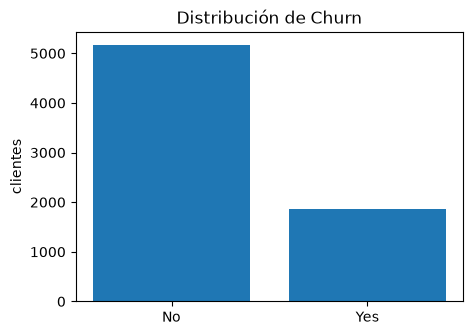

In [11]:
conteo = df['Churn'].value_counts()
print(conteo)
print()
print(round(df['Churn'].value_counts(normalize=True) * 100, 1))

plt.figure(figsize=(5, 3.5))
plt.bar(conteo.index, conteo.values)
plt.title('Distribución de Churn')
plt.ylabel('clientes')
plt.show()

**Conclusión: el problema está desbalanceado.** El 26,5% se va y el 73,5% se queda.

Un modelo que diga siempre "no se va" tendría 73,5% de accuracy sin haber aprendido nada. Por eso:
- **No vamos a usar accuracy como métrica principal.** Vamos a usar **AUC-ROC**, más **sensibilidad** (de los que se van, cuántos detectamos) y **especificidad**.
- Vamos a **estratificar** el train/test split y la validación cruzada, para que todas las particiones tengan 26,5% de churn.

## Paso 5: Variables numéricas
**5.1** Distribución de cada variable
Calculamos la **asimetría** si da igual a 0 es simétrica. Para ver la forma de cada variable, su escala y si hay outliers

In [12]:
df[numericas].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,6127.00,5846.00,7032.00
mean,32.54,64.66,2283.30
std,24.63,30.05,2266.77
min,0.00,18.70,18.80
25%,9.00,35.40,401.45
50%,29.00,70.38,1397.48
75%,56.00,89.69,3794.74
max,72.00,118.75,8684.80


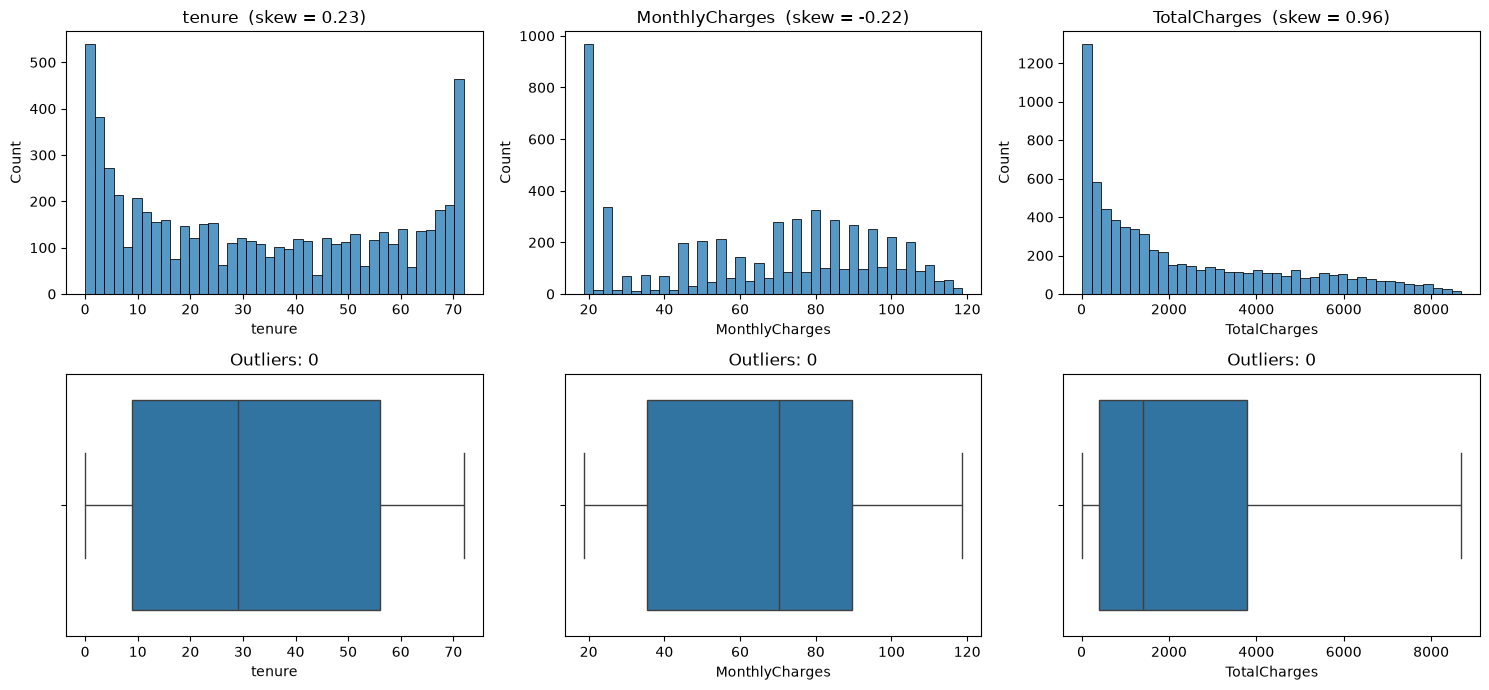

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i in range(3):
    col = numericas[i]
    datos = df[col].dropna()
    # histograma
    sns.histplot(datos, bins=40, ax=ax[0, i])
    ax[0, i].set_title(col + '  (skew = ' + str(round(skew(datos), 2)) + ')')
    # boxplot y cantidad de outliers
    sns.boxplot(x=datos, ax=ax[1, i])
    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1
    outliers = ((datos < q1 - 1.5 * iqr) | (datos > q3 + 1.5 * iqr)).sum()
    ax[1, i].set_title('Outliers: ' + str(outliers))
plt.tight_layout()
plt.show()

**Conclusión:**
- **`tenure`** (antigüedad, 0 a 72 meses) tiene forma de "U": muchos clientes nuevos y muchos muy antiguos. Son como dos grupos de clientes distintos.
- **`MonthlyCharges`** también tiene dos picos: uno cerca de 20 (clientes solo con teléfono) y otro cercano a los 80
- **`TotalCharges`** tiene asimetría a la derecha: muchos clientes gastaron poco en total (los nuevos) y pocos gastaron mucho.
- **No hay outliers** Entendemos que los valores extremos son clientes reales, no errores, así que no borramos nada.
- Las escalas son muy distintas (tenure llega a 72 y TotalCharges a 8.684). Para KNN, regresión logística, redes y PCA **hay que estandarizar**.

**5.2** Variables numéricas vs Churn
Queremos ver si los clientes que se van son distintos de los que se quedan: ¿son más nuevos?, ¿pagan más? Para eso comparamos los dos grupos en el mismo gráfico y miramos la mediana de cada uno.

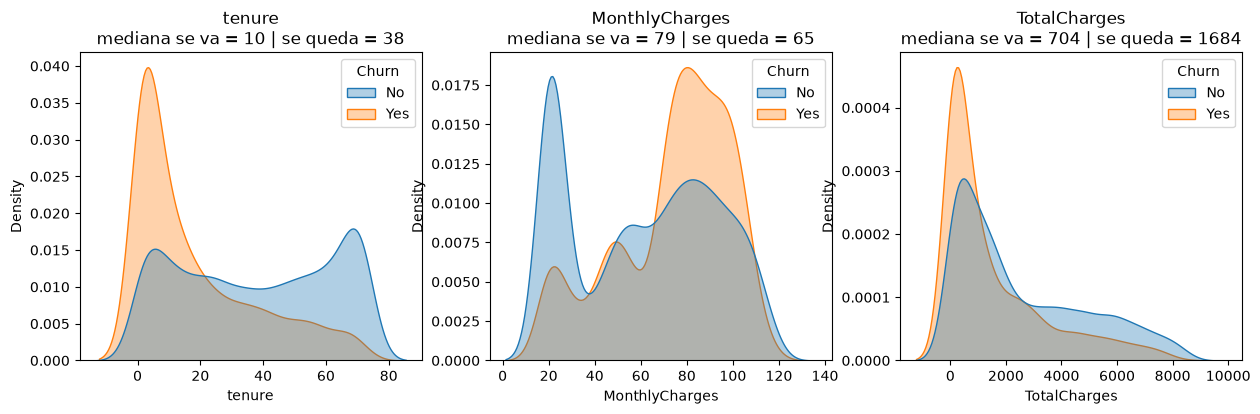

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in range(3):
    col = numericas[i]
    sns.kdeplot(data=df, x=col, hue='Churn', common_norm=False, fill=True, alpha=0.35,
             ax=ax[i])
    se_va = df[df['Churn'] == 'Yes'][col].dropna()
    se_queda = df[df['Churn'] == 'No'][col].dropna()
    ax[i].set_title(col + '\nmediana se va = ' + str(round(se_va.median())) + ' | se queda = '
                    + str(round(se_queda.median())))


plt.show()

**Conclusión:**
- **`tenure`** Los que se van tienen una antigüedad mediana de **10 meses**; los que se quedan, **38**. El churn pasa sobre todo en los primeros meses.
- **`MonthlyCharges`:** los que se van **pagan más por mes** (mediana $79 contra $65).
- **`TotalCharges`:** los que se van gastaron **menos en total**. 

Para verlo mejor, calculamos la tasa de churn por tramo de antigüedad:

tramo_tenure
0-6      52.6
7-12     37.4
13-24    29.4
25-36    22.1
37-48    19.4
49-60    14.8
61-72     6.4
Name: churn_num, dtype: float64


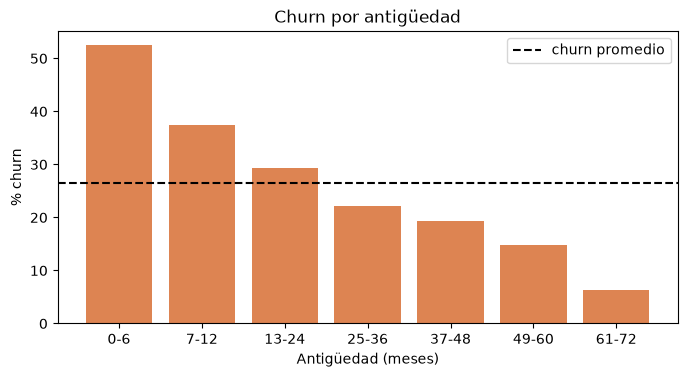

In [15]:
df['tramo_tenure'] = pd.cut(df['tenure'], bins=[-1, 6, 12, 24, 36, 48, 60, 72],
                            labels=['0-6', '7-12', '13-24', '25-36', '37-48', '49-60', '61-72'])
churn_tramo = df.groupby('tramo_tenure', observed=True)['churn_num'].mean() * 100
print(churn_tramo.round(1))

plt.figure(figsize=(8, 3.8))
plt.bar(churn_tramo.index.astype(str), churn_tramo.values, color='#DD8452')
plt.axhline(df['churn_num'].mean() * 100, ls='--', color='k', label='churn promedio')
plt.xlabel('Antigüedad (meses)')
plt.ylabel('% churn')
plt.title('Churn por antigüedad')
plt.legend()
plt.show()

**Conclusión:** de los clientes con menos de 6 meses se va **más de la mitad (53%)**, y de los que tienen más de 5 años solo el 6%. El churn baja muy rápido al principio y después se estabiliza: es una relación **no lineal**. Esto nos hace pensar que modelos que capten no linealidades, como los árboles, pueden andar bien.

## Paso 6: Variables categóricas vs Churn
Queremos saber qué características de los clientes tienen que ver con que se vayan. Para cada variable calculamos el % de clientes que se va en cada categoría. Por ejemplo: de los que tienen contrato mes a mes, ¿qué porcentaje se fue? ¿Y de los que tienen contrato anual?
Si en todas las categorías se va más o menos el mismo porcentaje, esa variable no influye. Si entre una categoría y otra hay mucha diferencia, la variable sí influye.
En los gráficos ponemos primero las variables donde más cambia el % de churn de una categoría a otra (por ejemplo, en Contract va de 43% a 3%) y al final las que casi no cambian (en gender es 26,5% contra 26,7%).

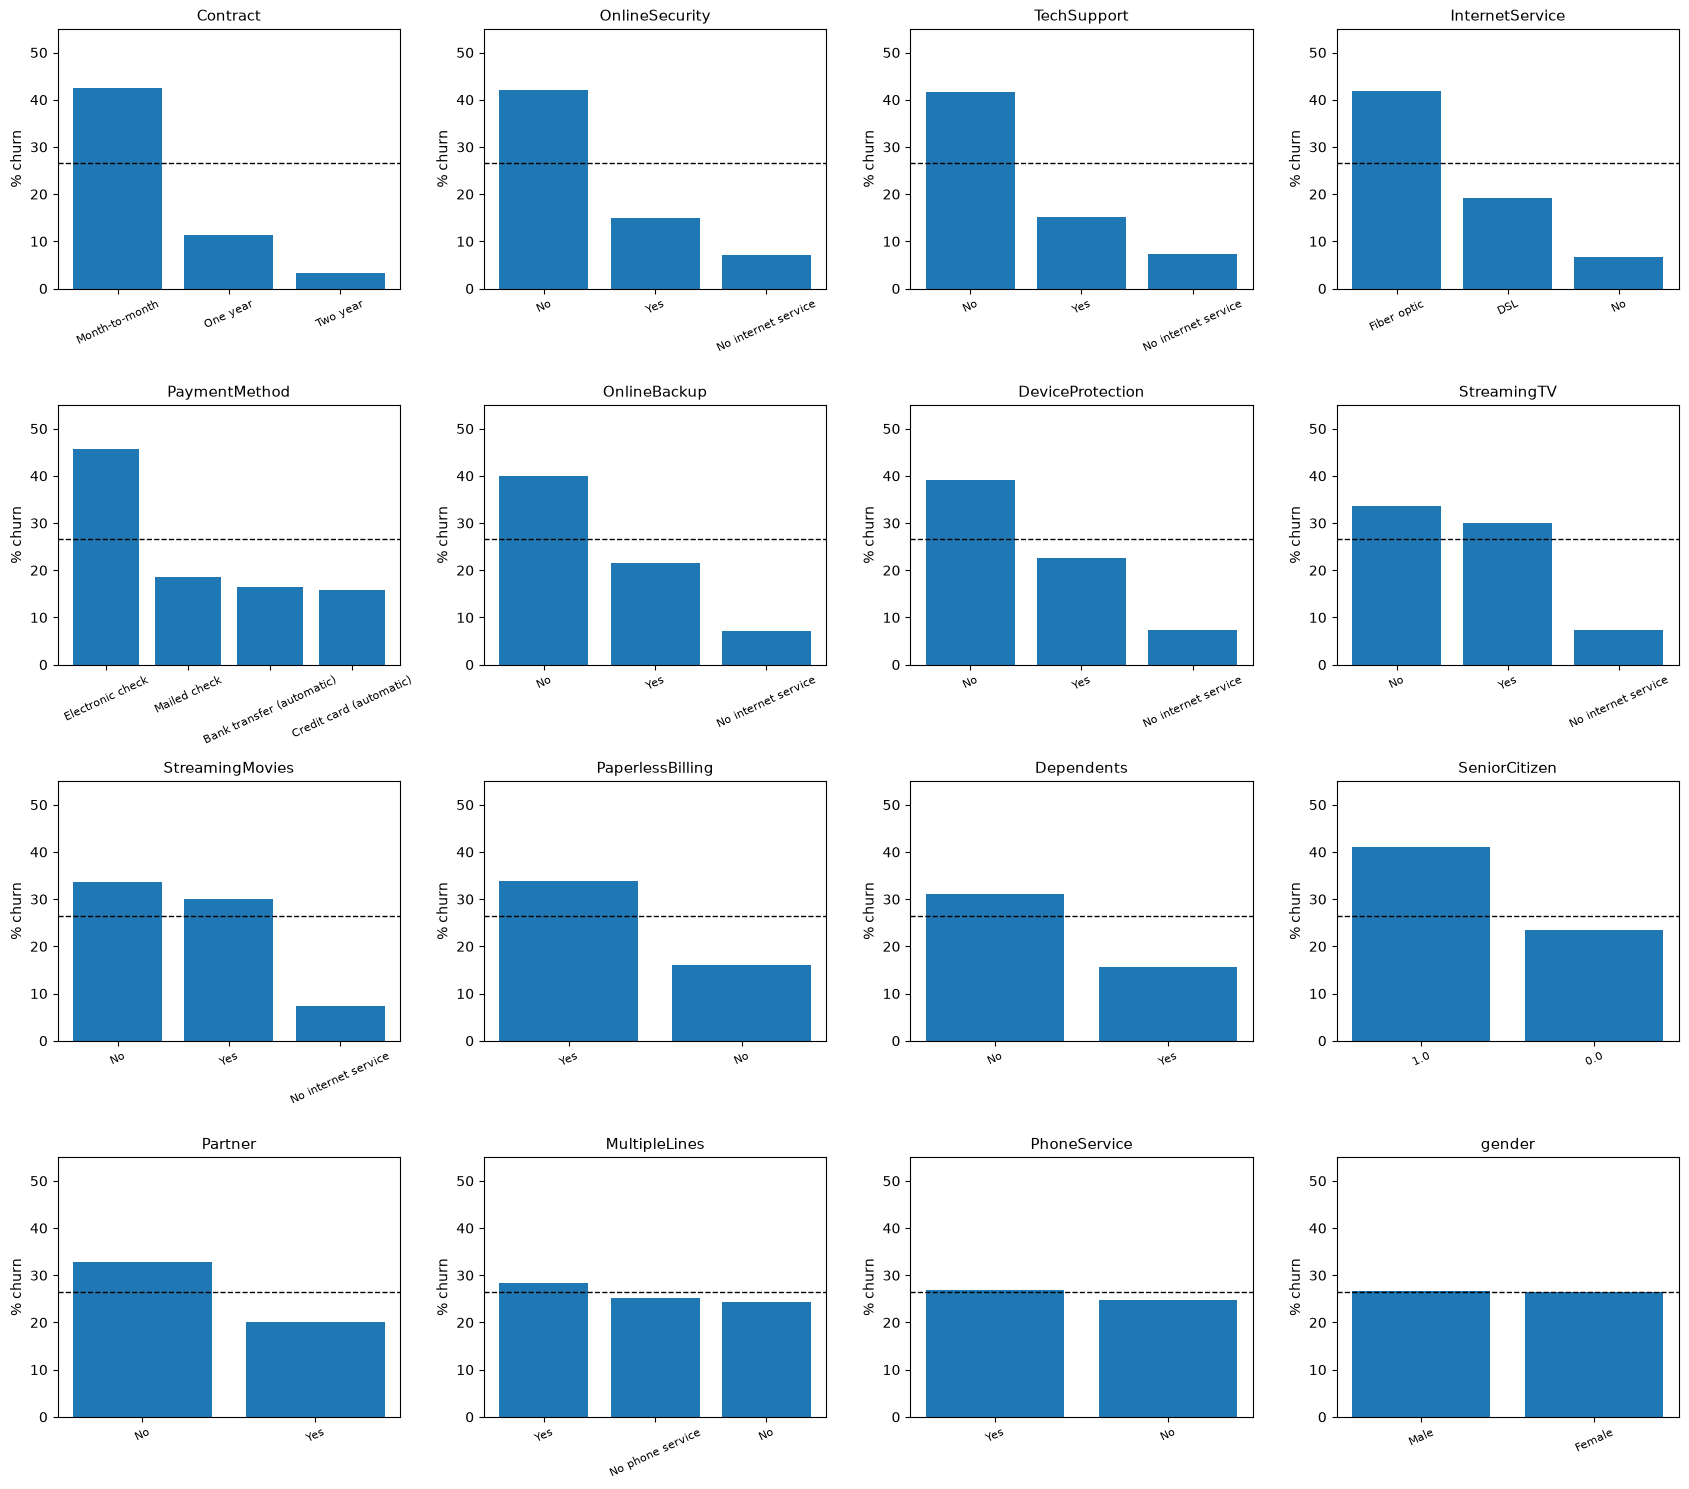

In [16]:
#Lista de variables categóricas, ordenadas de las que más diferencia muestran a las que menos
cols_cat = ['Contract', 'OnlineSecurity', 'TechSupport', 'InternetService',
            'PaymentMethod', 'OnlineBackup', 'DeviceProtection', 'StreamingTV',
            'StreamingMovies', 'PaperlessBilling', 'Dependents', 'SeniorCitizen',
            'Partner', 'MultipleLines', 'PhoneService', 'gender']

fig, ax = plt.subplots(4, 4, figsize=(17, 15))
ax = ax.ravel()
i = 0
for col in cols_cat:
    tasa = df.groupby(col)['churn_num'].mean().sort_values(ascending=False) * 100
    ax[i].bar(tasa.index.astype(str), tasa.values)
    ax[i].axhline(df['churn_num'].mean() * 100, ls='--', color='k', lw=1)
    ax[i].set_title(col, fontsize=11)
    ax[i].set_ylim(0, 55)
    ax[i].set_ylabel('% churn')
    ax[i].tick_params(axis='x', rotation=25, labelsize=8)
    i = i + 1
plt.tight_layout()
plt.show()

**Conclusiones (de las variables que más influyen a las que menos)**
1. **`Contract`** Con contrato **mes a mes se va el 43%**, con anual el 11% y con bianual solo el 3%. Tiene lógica: sin contrato irse no cuesta nada. Pasar clientes a contratos largos es una buena estrategia de retención.
2. **`OnlineSecurity` y `TechSupport`:** los que **no** tienen seguridad online o soporte técnico se van un 42%; los que sí los tienen, un 15%.
3. **`InternetService` :** con **fibra óptica se va el 42%**, con DSL el 19% y sin internet el 7%. Llama la atención porque la fibra es el mejor servicio. Puede ser un tema de precio (es la más cara) o de calidad.
4. **`PaymentMethod`:** con **cheque electrónico se va el 46%**; con los otros métodos, entre 16% y 19%. Los pagos automáticos (tarjeta, débito) retienen más.
5. **`OnlineBackup` y `DeviceProtection`:** mismo patrón que seguridad y soporte, pero más débil.
6. **`StreamingTV` y `StreamingMovies`:**  Entre tener o no streaming la diferencia es chica (30% vs 34%), así que el streaming en sí casi no aporta.
7. **`PaperlessBilling`, `Dependents`, `SeniorCitizen`, `Partner`:** asociación débil. Los jubilados (41%) y los que no tienen pareja ni hijos se van un poco más.
8. **`MultipleLines`, `PhoneService` y `gender`:** casi no tienen relación. **Hombres y mujeres se van igual.**

## Paso 7: Interacciones entre variables
Queremos entender el efecto entre variables por lo cual cruzamos las dos más fuertes (contrato e internet) y hacemos un scatter de tenure vs cargo mensual coloreado por churn.

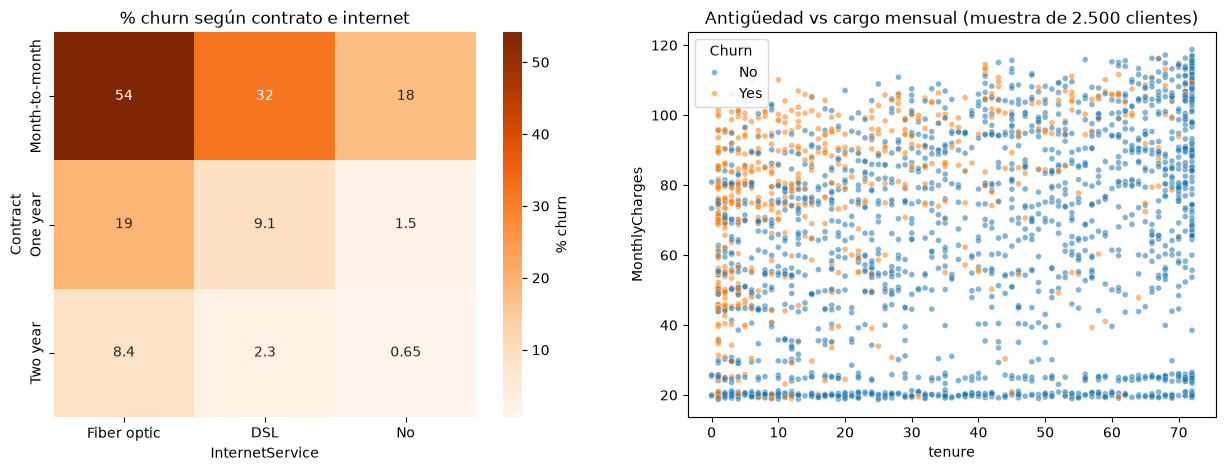

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
tabla = df.pivot_table(index='Contract', columns='InternetService', values='churn_num', aggfunc='mean') * 100
tabla = tabla.loc[['Month-to-month', 'One year', 'Two year'], ['Fiber optic', 'DSL', 'No']]
sns.heatmap(tabla, annot=True, cmap='Oranges', cbar_kws={'label': '% churn'}, ax=ax[0])
ax[0].set_title('% churn según contrato e internet')

muestra = df.dropna(subset=['tenure', 'MonthlyCharges']).sample(2500, random_state=0)
sns.scatterplot(data=muestra, x='tenure', y='MonthlyCharges', hue='Churn', alpha=0.55, s=18,
                 ax=ax[1])
ax[1].set_title('Antigüedad vs cargo mensual (muestra de 2.500 clientes)')
plt.show()

**Conclusión:**
- Con **mes a mes + fibra óptica se va el 54%**, más de la mitad. Con contrato bianual, en cambio, los de fibra casi no se van (8%). **El contrato "compensa" el riesgo de la fibra.**
- En el scatter, el churn (naranja) se concentra **arriba a la izquierda: clientes nuevos que pagan caro**. Los clientes viejos casi no se van aunque paguen mucho.
- Como hay interacciones, tiene sentido probar modelos de árboles, que las captan solos.

## Paso 8: Correlación entre las variables numéricas
Para ver si hay variables redundantes (multicolinealidad). Usamos **Pearson** (relación lineal).

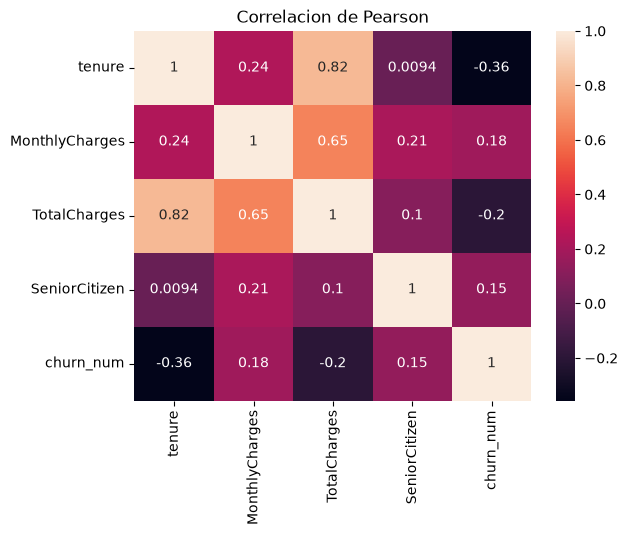

In [18]:
corr_matrix = df[numericas + ['SeniorCitizen', 'churn_num']].corr()

# visualizamos la matriz de correlacion
sns.heatmap(corr_matrix, annot=True)
plt.title('Correlacion de Pearson')
plt.show()

**Conclusión:**
- **`TotalCharges` está muy correlacionada con `tenure`** (0,82 Pearson)
  - En la regresión logística esto hace que los coeficientes sean inestables y difíciles de interpretar. La regularización (Ridge) ayuda.
  - También es un motivo para probar **PCA**: si hay información repetida, se puede representar en menos dimensiones.
- Con el churn, la que más correlaciona es `tenure` (−0,36), después `TotalCharges` (−0,20) y `MonthlyCharges` (+0,18). 

## Paso 9: ¿Influye la cantidad de servicios contratados?
Vimos que tener seguridad o soporte retiene. Queremos ver si pasa lo mismo con la cantidad total de servicios extra. Contamos los "Yes" en los 6 servicios de internet, solo para clientes que tienen internet.

cant_servicios
0    50.5
1    45.3
2    33.7
3    27.9
4    21.5
5    12.0
6     4.3
Name: churn_num, dtype: float64


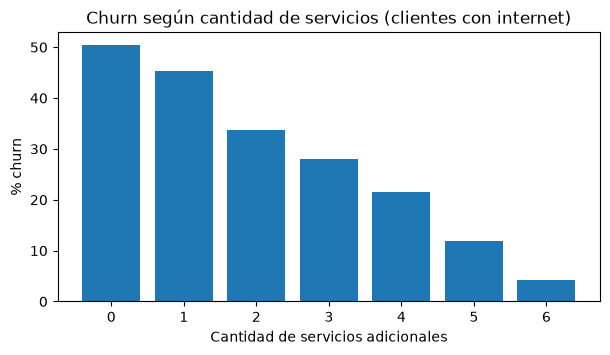

In [19]:
servicios = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
con_internet = df[df['InternetService'].isin(['DSL', 'Fiber optic'])].copy()
con_internet['cant_servicios'] = (con_internet[servicios] == 'Yes').sum(axis=1)
churn_servicios = con_internet.groupby('cant_servicios')['churn_num'].mean() * 100
print(churn_servicios.round(1))

plt.figure(figsize=(7, 3.5))
plt.bar(churn_servicios.index, churn_servicios.values)
plt.xlabel('Cantidad de servicios adicionales')
plt.ylabel('% churn')
plt.title('Churn según cantidad de servicios (clientes con internet)')
plt.show()

**Conclusión:** los clientes con internet pero **sin ningún servicio extra se van el 50%** de las veces; con 5 servicios, el 12%, y con los 6, apenas el 4%. Cuantos más servicios, más "atado" queda el cliente.

## Conclusiones del EDA

**Sobre la calidad de los datos:**
- Hay que borrar `Unnamed: 0` y no usar `customerID` en el modelo.
- `TotalCharges` tiene 11 blancos de clientes nuevos, que se reemplazan por 0.
- Hay entre 13% y 17% de faltantes por variable, y solo el 12% de las filas está completa. Por eso **imputamos en vez de borrar**: primero con reglas lógicas, y lo que quede con mediana/moda dentro del pipeline, ajustado solo en train para no tener data leakage.
- No hay outliers.

**Sobre el target:** está desbalanceado (26,5% / 73,5%). Usamos split y validación cruzada estratificados, AUC como métrica principal y miramos sensibilidad y especificidad.

**Perfil del cliente que se va:**
Cliente **nuevo** (menos de 12 meses), con contrato **mes a mes**, **fibra óptica**, que **paga caro**, paga con **cheque electrónico** y **no tiene seguridad ni soporte técnico**.

**Variables que casi no aportan:** `gender`, `PhoneService`, `MultipleLines`, y el streaming aporta poco más allá de `InternetService`.

**Para el modelado:** hay que estandarizar las numéricas y hacer one-hot de las categóricas. Hay relaciones no lineales e interacciones, así que comparamos modelos lineales contra árboles. También hay multicolinealidad, así que tiene sentido probar PCA.